In [1]:
import stlrom

begin_time: 0  end_time: 2.5
time:          0  value:          1  derivative:         -1
time:          1  value:     -1e-10  derivative:          0
time:          1  value:      1e-10  derivative:          1
time:          2  value:          1  derivative:         -4
time:       2.25  value:     -1e-10  derivative:          0
time:       2.25  value:      1e-10  derivative:          4
time:        2.5  value:          1  derivative:         -0

t=0.0: +1.000 (expected +1.000)
t=0.5: +0.500 (expected +0.500)
t=1.0: -0.000 (expected +0.000)
t=1.5: +0.500 (expected +0.500)
t=1.9: +0.900 (expected +0.900)


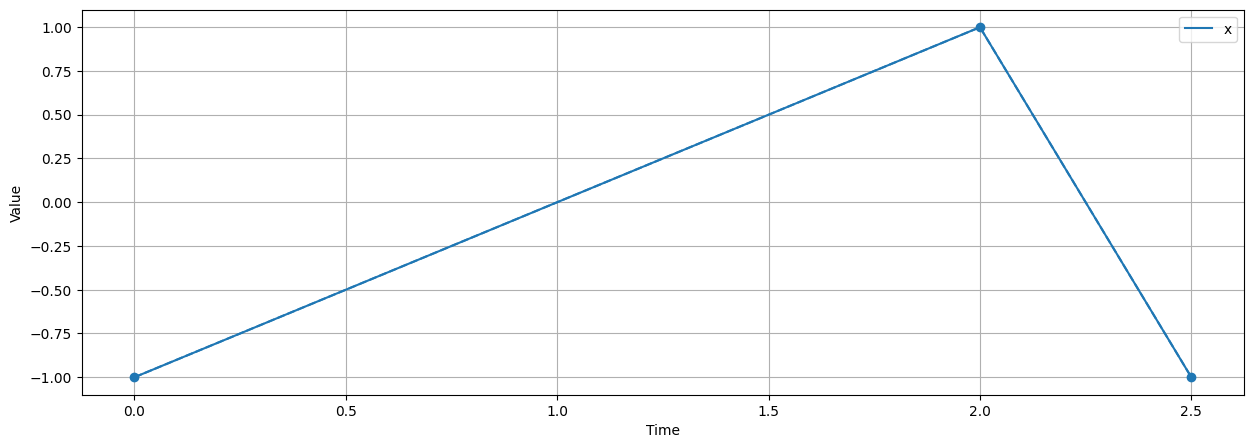

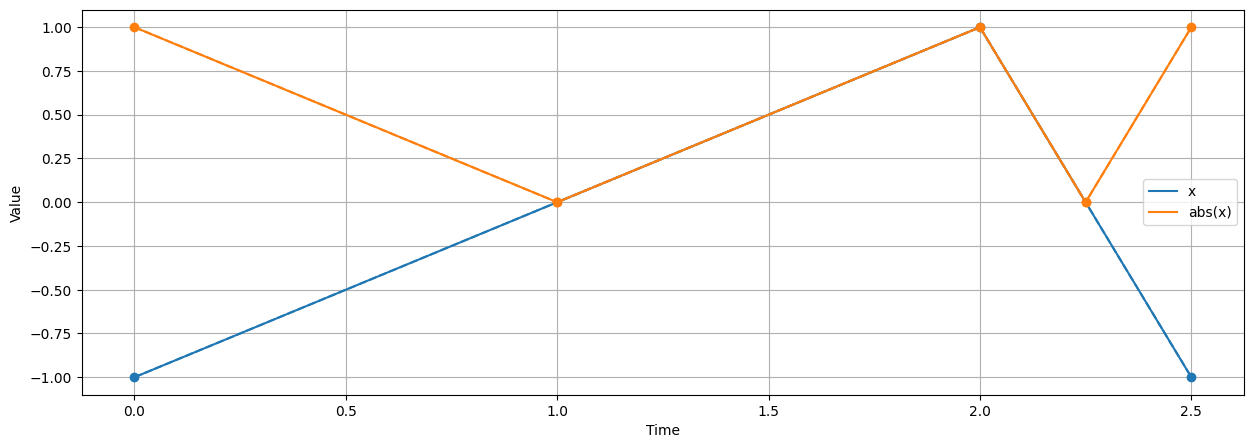

In [16]:
driver = stlrom.STLDriver()
driver.parse_string("signal x\nmu := abs(x[t]) > 0\n")

# one linear piece from -1 to 1, root at t = 1
driver.add_sample([0.0, -1.0], True)
driver.add_sample([2.0, 1.0], True)
driver.add_sample([2.5, -1.0], True)

rob = driver.get_rob_signal("mu", 0.0, 2.5)

driver.plot_signal('x', draw_samples=True)
ax = driver.plot_signal('x', draw_samples=True)
ax = rob.plot(ax=ax, draw_samples=True, label='abs(x)')
print(rob)
for t in [0.0, 0.5, 1.0, 1.5, 1.9]:
    print(f"t={t}: {rob.value_at(t):+.3f} (expected {abs(t - 1):+.3f})")